# 🧠 Notebook 4 — Fine-tuning de BERT para Detección de Phishing

## ¿Qué es BERT y por qué usarlo?

**BERT** (Bidirectional Encoder Representations from Transformers) es un modelo de lenguaje pre-entrenado por Google en 2018.

### Diferencias clave vs. modelos clásicos:

| Característica | TF-IDF + ML clásico | BERT |
|---|---|---|
| Representación | Frecuencia de palabras | Contexto completo de cada palabra |
| 'bank account' | Dos palabras separadas | Frase con significado específico |
| Pre-entrenamiento | No | Sí — ya sabe inglés antes de ver tus datos |
| Velocidad | Muy rápido | Lento (necesita GPU) |
| Generalización | Buena | Excelente — detecta phishing nuevo que no está en el train |

### ¿Qué es Fine-tuning?
BERT ya fue entrenado con millones de páginas web (Wikipedia, Books). Ya entiende el idioma inglés. **Fine-tuning** es ajustar ese modelo pre-entrenado para tu tarea específica (clasificar phishing) con relativamente pocos datos adicionales.

Es como contratar a alguien que ya sabe inglés y enseñarle solo tu dominio específico — mucho más eficiente que enseñarle inglés desde cero.

### Tu GPU: RTX 5060 con 8GB VRAM
- Suficiente para BERT-base (110M parámetros)
- Usaremos `fp16` (precisión mixta) para reducir memoria a la mitad
- Batch size recomendado: 16-32 con max_length=128

---

## 1. Verificar GPU y Configuración de CUDA

Antes de empezar, confirmamos que PyTorch detecta correctamente tu RTX 5060.

In [8]:
import torch

# torch.cuda.is_available() devuelve True si PyTorch detecta una GPU con CUDA
if torch.cuda.is_available():
    gpu_name   = torch.cuda.get_device_name(0)   # nombre de la GPU
    gpu_mem_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3  # VRAM en GB
    cuda_ver   = torch.version.cuda
    
    print(f'✅ GPU detectada: {gpu_name}')
    print(f'   VRAM total   : {gpu_mem_gb:.1f} GB')
    print(f'   CUDA version : {cuda_ver}')
    print(f'   PyTorch      : {torch.__version__}')
    
    # Configurar el dispositivo — todas las operaciones ocurrirán aquí
    DEVICE = torch.device('cuda')
else:
    print('⚠️  GPU no detectada — usando CPU (será muy lento)')
    print('   Verifica que PyTorch esté instalado con soporte CUDA:')
    print('   pip install torch --index-url https://download.pytorch.org/whl/cu128')
    DEVICE = torch.device('cpu')

print(f'\nDispositivo activo: {DEVICE}')

✅ GPU detectada: NVIDIA GeForce RTX 5060 Laptop GPU
   VRAM total   : 8.0 GB
   CUDA version : 12.8
   PyTorch      : 2.11.0+cu128

Dispositivo activo: cuda


## 2. Importar Librerías

### Nuevas librerías en este notebook:

- **transformers** (Hugging Face): Librería con modelos pre-entrenados (BERT, GPT, RoBERTa, etc.)
  - `BertTokenizer`: Convierte texto a tokens de la forma que BERT entiende
  - `BertForSequenceClassification`: BERT con una capa de clasificación encima
  - `get_linear_schedule_with_warmup`: Programador de learning rate
- **torch.utils.data**: DataLoader, Dataset — forma estándar de cargar datos en batches
- **torch.cuda.amp**: Automatic Mixed Precision — mezcla fp16 y fp32 para ahorrar VRAM

In [9]:
import sys
import subprocess
import os

print('Instalando paquetes en el kernel actual...')
print(f'Python: {sys.executable}\n')

# Ruta al archivo .whl descargado en Downloads
ruta_wheel_local = os.path.expanduser(r"~\Downloads\torch-2.11.0+cu128-cp312-cp312-win_amd64.whl")

if os.path.exists(ruta_wheel_local):
    print(f'✅ Archivo encontrado: {ruta_wheel_local}\n')
    
    # 1. Limpiar caché corrupta
    print('1. Limpiando caché de pip...')
    subprocess.check_call([sys.executable, "-m", "pip", "cache", "purge"])
    
    # 2. Instalar torch desde el archivo LOCAL
    print(f'2. Instalando torch desde archivo local...')
    subprocess.check_call([sys.executable, "-m", "pip", "install", ruta_wheel_local])
    
    # 3. Instalar transformers y scikit-learn
    print('\n3. Instalando transformers, scikit-learn y tqdm...')
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", 
                          "transformers", "scikit-learn", "tqdm"])
    
    print('\n✅ Todas las dependencias instaladas correctamente')
else:
    print(f'❌ Archivo no encontrado en: {ruta_wheel_local}')
    print('   Verifica la ruta o descarga desde:')
    print('   https://download.pytorch.org/whl/cu128/torch-2.11.0%2Bcu128-cp312-cp312-win_amd64.whl')

Instalando paquetes en el kernel actual...
Python: c:\Users\danye\AppData\Local\Programs\Python\Python312\python.exe

✅ Archivo encontrado: C:\Users\danye\Downloads\torch-2.11.0+cu128-cp312-cp312-win_amd64.whl

1. Limpiando caché de pip...
2. Instalando torch desde archivo local...

3. Instalando transformers, scikit-learn y tqdm...

✅ Todas las dependencias instaladas correctamente


In [36]:

# Ahora importar las librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import time
import warnings
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast

from transformers import (
    BertTokenizer,
    BertForSequenceClassification,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, f1_score

import joblib

warnings.filterwarnings('ignore')

print(f'✅ Librerías cargadas')
print(f'   torch     : {torch.__version__}')

try:
    import transformers
    print(f'   transformers: {transformers.__version__}')
except ImportError:
    print('❌ transformers no instalado')

✅ Librerías cargadas
   torch     : 2.11.0+cu128
   transformers: 5.6.2


## 3. Configuración Global

Definimos todos los hiperparámetros en un solo lugar para fácil experimentación.

### ¿Qué es un hiperparámetro?
A diferencia de los parámetros del modelo (pesos que aprende durante entrenamiento), los hiperparámetros son configuraciones que **nosotros elegimos** antes de entrenar:

| Hiperparámetro | Valor elegido | Por qué |
|---|---|---|
| `MAX_LEN` | 128 | BERT acepta hasta 512, pero 128 cubre la mayoría de emails y usa 4x menos memoria |
| `BATCH_SIZE` | 16 | Compromiso entre velocidad y VRAM disponible (8GB) |
| `EPOCHS` | 3 | BERT fine-tuning raramente necesita más de 3-5 epochs |
| `LR` | 2e-5 | Recomendación del paper original de BERT para fine-tuning |
| `WARMUP_STEPS` | 10% | Calentamiento gradual del learning rate — estabiliza entrenamiento |

In [11]:
# === CONFIGURACIÓN ===

# Modelo base a usar
# 'bert-base-uncased' → uncased = sin distinción de mayúsculas (recomendado para phishing)
# Alternativas: 'bert-base-cased', 'distilbert-base-uncased' (50% más rápido, 97% del rendimiento)
MODEL_NAME = 'bert-base-uncased'

# Máxima longitud en tokens
# El tokenizador dividirá textos largos en múltiples tokens WordPiece
# 128 cubre bien emails de longitud media; usar 256 si muchos emails importantes son largos
MAX_LEN = 128

# Número de muestras por lote
# Con 8GB VRAM y MAX_LEN=128 → BATCH_SIZE=16-32 funciona bien
# Si obtienes OOM (Out of Memory), reduce a 8
BATCH_SIZE = 16

# Número de épocas — cuántas veces el modelo ve TODO el dataset de entrenamiento
EPOCHS = 3

# Learning rate — cuánto ajustan los pesos en cada paso
# Para BERT fine-tuning: entre 1e-5 y 5e-5 según el paper original
LEARNING_RATE = 2e-5

# Pasos de warmup — el LR sube gradualmente desde 0 durante los primeros N pasos
# Esto estabiliza el entrenamiento al inicio
WARMUP_RATIO = 0.1  # 10% del total de pasos

# Tamaño del dataset de entrenamiento
# None = usar todos | int = muestreo (ej: 20_000 para prueba rápida)
SAMPLE_SIZE = None

# Directorio para guardar el modelo
MODEL_OUTPUT_DIR = '../models/bert_phishing'

# Semilla para reproducibilidad en PyTorch
SEED = 42
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)

print('=== CONFIGURACIÓN ===')
print(f'  Modelo base   : {MODEL_NAME}')
print(f'  Max tokens    : {MAX_LEN}')
print(f'  Batch size    : {BATCH_SIZE}')
print(f'  Épocas        : {EPOCHS}')
print(f'  Learning rate : {LEARNING_RATE}')
print(f'  Dispositivo   : {DEVICE}')
print(f'  Directorio    : {MODEL_OUTPUT_DIR}')

=== CONFIGURACIÓN ===
  Modelo base   : bert-base-uncased
  Max tokens    : 128
  Batch size    : 16
  Épocas        : 3
  Learning rate : 2e-05
  Dispositivo   : cuda
  Directorio    : ../models/bert_phishing


## 4. Cargar y Preparar los Datos

Para BERT usamos el texto con limpieza **suave** (sin eliminar stopwords, sin eliminar puntuación). BERT necesita el contexto completo del lenguaje.

In [16]:
import re, html

def limpiar_para_bert(text: str) -> str:
    """
    Limpieza suave para BERT:
    - Removemos HTML (no tiene significado lingüístico)
    - Normalizamos URLs y emails a tokens especiales
    - Mantenemos: mayúsculas/minúsculas, puntuación, stopwords, números
      (BERT los usa para entender contexto)
    """
    if not isinstance(text, str):
        return ''
    # Decodificar entidades HTML
    text = html.unescape(text)
    # Remover tags HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Normalizar URLs a token especial
    text = re.sub(r'https?://\S+|www\.\S+', '[URL]', text, flags=re.IGNORECASE)
    # Normalizar emails a token especial
    text = re.sub(r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}', '[EMAIL]', text)
    # Normalizar espacios múltiples
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# Cargar datos
DATA_PATH = '../data/processed/merged_phishing_full.csv'
df = pd.read_csv(DATA_PATH, usecols=['subject', 'body', 'label'], low_memory=False)
df = df.dropna(subset=['label'])
df['label'] = df['label'].astype(int)

# Aplicar limpieza suave y combinar subject + body
df['subject'] = df['subject'].fillna('').astype(str).apply(limpiar_para_bert)
df['body']    = df['body'].fillna('').astype(str).apply(limpiar_para_bert)
df['texto']   = df['subject'] + ' ' + df['body']

# Truncar texto a 1000 caracteres para que el tokenizador sea más rápido
# BERT cortará en MAX_LEN tokens de todas formas, pero reducir chars acelera el tokenizador
df['texto'] = df['texto'].str[:1000]

print(f'Dataset preparado: {len(df):,} registros')

# Muestreo opcional para pruebas rápidas
if SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=SEED, stratify=df['label'])
    print(f'  Muestra aplicada: {SAMPLE_SIZE:,} registros')

# Split estratificado train/validation/test (70/15/15)
# Usamos dos splits: primero separamos test, luego dividimos el resto en train+val
df_train_val, df_test = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df['label'])
df_train, df_val      = train_test_split(df_train_val, test_size=0.176, random_state=SEED,
                                          stratify=df_train_val['label'])
# 0.176 de 0.85 ≈ 0.15 del total

print(f'\nSplit:')
print(f'  Train     : {len(df_train):,}')
print(f'  Validation: {len(df_val):,}')
print(f'  Test      : {len(df_test):,}')

Dataset preparado: 131,339 registros

Split:
  Train     : 91,989
  Validation: 19,649
  Test      : 19,701


## 5. Tokenización con BERT

### ¿Qué es un token en BERT?
BERT usa **WordPiece tokenization** — divide palabras en sub-palabras:
- 'phishing' → ['phi', '##shin', '##g'] (si es una palabra poco común)
- 'email' → ['email'] (si está en el vocabulario)
- '[CLS] texto [SEP]' → tokens especiales de inicio y fin

### Tokens especiales:
- `[CLS]`: Clasificación — el primer token, cuya representación final se usa para clasificar el email
- `[SEP]`: Separador — marca el fin de la secuencia
- `[PAD]`: Padding — rellena secuencias cortas hasta MAX_LEN
- `attention_mask`: 1 = token real, 0 = padding (BERT ignora los 0s)

### ¿Por qué no podemos tokenizar dentro del modelo?
El tokenizador convierte strings a IDs numéricos — es un paso de preprocesamiento, no parte del modelo de PyTorch.

In [17]:
print(f'Descargando tokenizador {MODEL_NAME}...')
print('(La primera vez descarga ~500MB de archivos del modelo)')

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

print(f'✅ Tokenizador cargado')
print(f'   Vocabulario: {tokenizer.vocab_size:,} tokens')

# === DEMOSTRACIÓN DEL TOKENIZADOR ===
ejemplo = "Click HERE to verify your bank account immediately! http://free-prize.com"
tokens  = tokenizer.tokenize(ejemplo)
ids     = tokenizer.encode(ejemplo, add_special_tokens=True)

print(f'\nEjemplo: {ejemplo}')
print(f'Tokens  : {tokens}')
print(f'IDs     : {ids[:10]}...')
print(f'Total de tokens (incluye [CLS] y [SEP]): {len(ids)}')

Descargando tokenizador bert-base-uncased...
(La primera vez descarga ~500MB de archivos del modelo)
✅ Tokenizador cargado
   Vocabulario: 30,522 tokens

Ejemplo: Click HERE to verify your bank account immediately! http://free-prize.com
Tokens  : ['click', 'here', 'to', 'verify', 'your', 'bank', 'account', 'immediately', '!', 'http', ':', '/', '/', 'free', '-', 'prize', '.', 'com']
IDs     : [101, 11562, 2182, 2000, 20410, 2115, 2924, 4070, 3202, 999]...
Total de tokens (incluye [CLS] y [SEP]): 20


## 6. Dataset de PyTorch

### ¿Qué es un `Dataset` en PyTorch?
Es una clase que encapsula tus datos y define cómo acceder a cada muestra individualmente. PyTorch requiere esta interfaz para poder cargar datos en batches eficientemente.

Mínimo debes implementar:
- `__len__()`: cuántas muestras hay
- `__getitem__(idx)`: devuelve la muestra en la posición `idx`

In [18]:
class PhishingDataset(Dataset):
    """
    Dataset de PyTorch para clasificación de phishing con BERT.
    
    Tokeniza y prepara los datos en el formato que espera BERT:
    - input_ids      : secuencia de IDs de tokens
    - attention_mask : 1 para tokens reales, 0 para padding
    - labels         : etiqueta de clase (0=HAM, 1=PHISHING)
    """
    
    def __init__(self, textos, labels, tokenizer, max_len):
        """
        Parámetros:
            textos    : lista/Serie de strings con el texto de cada email
            labels    : lista/Serie de 0s y 1s
            tokenizer : tokenizador BERT ya cargado
            max_len   : longitud máxima en tokens
        """
        self.textos    = textos.reset_index(drop=True)  # resetear índice por seguridad
        self.labels    = labels.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len   = max_len
    
    def __len__(self):
        """Devuelve el número total de muestras en el dataset."""
        return len(self.textos)
    
    def __getitem__(self, idx):
        """
        Devuelve la muestra en la posición `idx` como diccionario de tensores.
        
        Este método es llamado por el DataLoader para cada muestra del batch.
        """
        texto = str(self.textos[idx])
        label = int(self.labels[idx])
        
        # tokenizer.encode_plus es la función principal de tokenización
        # truncation=True  → cortar si el texto supera max_length
        # padding='max_length' → rellenar con [PAD] si el texto es más corto
        # return_tensors='pt' → devolver tensores de PyTorch (no listas de Python)
        encoding = self.tokenizer(
            texto,
            max_length          = self.max_len,
            truncation          = True,           # cortar texto largo
            padding             = 'max_length',    # rellenar texto corto
            return_attention_mask = True,          # incluir máscara de atención
            return_tensors      = 'pt',            # formato PyTorch tensor
        )
        
        return {
            # squeeze(0) elimina la dimensión extra que add encode_plus
            # antes: shape [1, max_len] → después: shape [max_len]
            'input_ids'      : encoding['input_ids'].squeeze(0),
            'attention_mask' : encoding['attention_mask'].squeeze(0),
            # torch.tensor convierte el int de Python a un tensor escalar
            'labels'         : torch.tensor(label, dtype=torch.long),
        }


# Crear los tres datasets
train_dataset = PhishingDataset(df_train['texto'], df_train['label'], tokenizer, MAX_LEN)
val_dataset   = PhishingDataset(df_val['texto'],   df_val['label'],   tokenizer, MAX_LEN)
test_dataset  = PhishingDataset(df_test['texto'],  df_test['label'],  tokenizer, MAX_LEN)

print(f'Dataset de entrenamiento: {len(train_dataset):,} muestras')
print(f'Dataset de validación   : {len(val_dataset):,} muestras')
print(f'Dataset de prueba       : {len(test_dataset):,} muestras')

# Mostrar un ejemplo para verificar
ejemplo = train_dataset[0]
print(f'\nEjemplo de item del dataset:')
print(f'  input_ids shape      : {ejemplo["input_ids"].shape}')
print(f'  attention_mask shape : {ejemplo["attention_mask"].shape}')
print(f'  label                : {ejemplo["labels"].item()}')

Dataset de entrenamiento: 91,989 muestras
Dataset de validación   : 19,649 muestras
Dataset de prueba       : 19,701 muestras

Ejemplo de item del dataset:
  input_ids shape      : torch.Size([128])
  attention_mask shape : torch.Size([128])
  label                : 1


## 7. DataLoader

### ¿Qué hace el DataLoader?
El DataLoader toma el Dataset y lo divide en **batches** (lotes):
- En lugar de pasar los 100k emails de una vez (no cabe en memoria), pasamos de a `BATCH_SIZE` emails
- `shuffle=True` en entrenamiento: mezcla el orden en cada época para que el modelo no aprenda el orden
- `num_workers`: procesos paralelos para cargar datos — en Windows recomendamos 0 o 2

In [19]:
# num_workers > 0 acelera la carga de datos al paralelizarla
# En Windows a veces da problemas con multiprocessing → usar 0 si hay errores
NUM_WORKERS = 0  # seguro para Windows; cambiar a 2-4 si tu OS lo permite

train_loader = DataLoader(
    train_dataset,
    batch_size  = BATCH_SIZE,
    shuffle     = True,         # mezclar en cada época (SOLO para train)
    num_workers = NUM_WORKERS,
    pin_memory  = True,         # acelera la transferencia CPU→GPU
)

val_loader = DataLoader(
    val_dataset,
    batch_size  = BATCH_SIZE * 2,  # podemos usar batch más grande en validación (no hay gradientes)
    shuffle     = False,            # no mezclar en validación/test
    num_workers = NUM_WORKERS,
    pin_memory  = True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size  = BATCH_SIZE * 2,
    shuffle     = False,
    num_workers = NUM_WORKERS,
    pin_memory  = True,
)

print(f'Batches por época (train): {len(train_loader):,}')
print(f'Batches de validación    : {len(val_loader):,}')
print(f'Total de pasos de entrenamiento: {len(train_loader) * EPOCHS:,}')

Batches por época (train): 5,750
Batches de validación    : 615
Total de pasos de entrenamiento: 17,250


## 8. Cargar Modelo BERT

`BertForSequenceClassification` es BERT-base con una **capa lineal** encima del token `[CLS]`:

```
Texto → Tokenizador → BERT encoder (12 capas) → [CLS] vector (768 dims) → Lineal → [HAM, PHISHING]
```

La capa lineal convierte el vector de 768 dimensiones en 2 valores (logits): uno para HAM y uno para PHISHING. La clase con el logit más alto es la predicción.

In [20]:
print(f'Cargando modelo {MODEL_NAME}...')

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels = 2,            # 2 clases: HAM (0) y PHISHING (1)
    output_attentions = False, # no necesitamos los pesos de atención para esta tarea
    output_hidden_states = False,  # no necesitamos capas intermedias
)

# Mover el modelo a la GPU
# .to(DEVICE) copia todos los tensores del modelo a la memoria de la GPU
model = model.to(DEVICE)

# Contar parámetros
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'✅ Modelo cargado en {DEVICE}')
print(f'   Parámetros totales    : {total_params/1e6:.1f}M')
print(f'   Parámetros entrenables: {trainable_params/1e6:.1f}M')

# Estimar VRAM necesaria (muy aproximado)
# fp16: 2 bytes por parámetro para pesos + 2 para gradientes + overhead
print(f'   VRAM estimada (fp16)  : ~{trainable_params * 4 / 1024**3:.1f} GB')

Cargando modelo bert-base-uncased...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5019.31it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

✅ Modelo cargado en cuda
   Parámetros totales    : 109.5M
   Parámetros entrenables: 109.5M
   VRAM estimada (fp16)  : ~0.4 GB


## 9. Optimizador y Scheduler de Learning Rate

### AdamW — El optimizador estándar para transformers
**Adam** (Adaptive Moment Estimation) adapta la tasa de aprendizaje por parámetro. **AdamW** añade weight decay correctamente (regularización que penaliza pesos grandes).

### Linear Warmup Scheduler
El learning rate no permanece constante durante el entrenamiento:
1. **Warmup**: Sube linealmente de 0 a `LEARNING_RATE` durante los primeros N pasos — evita actualizaciones grandes e inestables al inicio
2. **Decay**: Baja linealmente de `LEARNING_RATE` a 0 hasta el final — refinamiento gradual

In [21]:
from torch.optim import AdamW

# === OPTIMIZADOR ===
# weight_decay: regularización L2 — penaliza pesos muy grandes (evita overfitting)
# eps: epsilon para estabilidad numérica (evita división por cero)
optimizer = AdamW(
    model.parameters(),
    lr           = LEARNING_RATE,
    weight_decay = 0.01,    # regularización L2
    eps          = 1e-8,    # epsilon para estabilidad
)

# === SCHEDULER ===
total_steps   = len(train_loader) * EPOCHS  # pasos totales de entrenamiento
warmup_steps  = int(total_steps * WARMUP_RATIO)  # 10% para warmup

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = warmup_steps,
    num_training_steps = total_steps,
)

print(f'Optimizador : AdamW (lr={LEARNING_RATE}, weight_decay=0.01)')
print(f'Total pasos : {total_steps:,}')
print(f'Warmup pasos: {warmup_steps:,} ({WARMUP_RATIO*100:.0f}%)')

# === MIXED PRECISION (fp16) ===
# GradScaler evita que los gradientes se vuelvan cero (underflow) con fp16
# En fp16 los valores muy pequeños pueden redondearse a 0, haciendo que el modelo no aprenda
# GradScaler escala los gradientes hacia arriba antes del backward pass y los revierte después
scaler = GradScaler()
print(f'Mixed Precision (fp16): ✅ activado')

Optimizador : AdamW (lr=2e-05, weight_decay=0.01)
Total pasos : 17,250
Warmup pasos: 1,725 (10%)
Mixed Precision (fp16): ✅ activado


## 10. Funciones de Entrenamiento y Evaluación

### El Loop de Entrenamiento

En cada **paso** (step):
1. Cargamos un batch de la GPU
2. Hacemos **forward pass**: el modelo procesa el texto y genera predicciones
3. Calculamos la **loss** (cross-entropy): qué tan lejos estamos de las etiquetas reales
4. Hacemos **backward pass**: calculamos gradientes (cómo cambiar cada peso para reducir la loss)
5. **Gradient clipping**: limitamos el tamaño de los gradientes para evitar explosión
6. **Optimizer step**: actualizamos los pesos
7. **Scheduler step**: actualizamos el learning rate

In [29]:
def train_epoch(model, loader, optimizer, scheduler, scaler, device):
    """
    Entrena el modelo por UNA época completa.
    Devuelve la loss promedio de la época.
    """
    model.train()  # poner modelo en modo entrenamiento (activa Dropout, BatchNorm, etc.)
    total_loss = 0
    total_correct = 0
    total_samples = 0
    
    # tqdm muestra barra de progreso sobre el DataLoader
    progress = tqdm(loader, desc='  Entrenando', leave=False)
    
    for batch in progress:
        # Mover datos de CPU a GPU
        # .to(device) transfiere tensores a la memoria de la GPU
        input_ids      = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels         = batch['labels'].to(device)
        
        # Limpiar gradientes del paso anterior
        # Esto es NECESARIO — PyTorch acumula gradientes por defecto
        optimizer.zero_grad()
        
        # Forward pass con mixed precision (fp16)
        # autocast convierte automáticamente operaciones elegibles a fp16
        # Esto reduce el uso de VRAM casi a la mitad y acelera el cómputo en GPU
        with autocast():
            outputs = model(
                input_ids      = input_ids,
                attention_mask = attention_mask,
                labels         = labels,   # pasar labels hace que BERT calcule la loss automáticamente
            )
            loss = outputs.loss  # cross-entropy loss calculada internamente por BERT
        
        # Backward pass con scaler para mixed precision
        # scaler.scale(loss).backward() escala la loss antes de calcular gradientes
        scaler.scale(loss).backward()
        
        # Gradient clipping: limitar la norma máxima de los gradientes a 1.0
        # Sin esto, gradientes muy grandes pueden desestabilizar el entrenamiento
        scaler.unscale_(optimizer)  # desescalar antes de clipear
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        # Actualizar pesos con el optimizador
        scaler.step(optimizer)
        scaler.update()   # ajusta el factor de escala para el siguiente paso
        scheduler.step()  # actualizar el learning rate
        
        # Acumular métricas
        total_loss += loss.item()
        preds = outputs.logits.argmax(dim=-1)  # clase con mayor logit
        total_correct += (preds == labels).sum().item()
        total_samples += len(labels)
        
        # Actualizar descripción de la barra de progreso
        progress.set_postfix({'loss': f'{loss.item():.4f}',
                              'lr': f'{scheduler.get_last_lr()[0]:.2e}'})
    
    avg_loss = total_loss / len(loader)
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


def evaluate(model, loader, device):
    """
    Evalúa el modelo en un conjunto de datos (validación o test).
    Devuelve loss, accuracy, todas las predicciones y probabilidades.
    """
    model.eval()  # modo evaluación: desactiva Dropout
    total_loss = 0
    all_preds  = []
    all_labels = []
    all_probs  = []
    
    # torch.no_grad() desactiva el cálculo de gradientes
    # Ahorra memoria y acelera la evaluación — no necesitamos gradientes aquí
    with torch.no_grad():
        for batch in tqdm(loader, desc='  Evaluando', leave=False):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)
            
            with autocast():
                outputs = model(
                    input_ids      = input_ids,
                    attention_mask = attention_mask,
                    labels         = labels,
                )
            
            total_loss += outputs.loss.item()
            
            # softmax convierte logits a probabilidades que suman 1
            probs = torch.softmax(outputs.logits, dim=-1)
            preds = probs.argmax(dim=-1)
            
            # .cpu().numpy() mueve el tensor de GPU a CPU y lo convierte a numpy
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_probs.append(probs[:, 1].cpu().numpy())  # prob de clase phishing
    
    # Concatenar los resultados de todos los batches
    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    all_probs  = np.concatenate(all_probs)
    
    avg_loss = total_loss / len(loader)
    accuracy = (all_preds == all_labels).mean()
    
    return avg_loss, accuracy, all_preds, all_labels, all_probs


print('✅ Funciones de entrenamiento y evaluación definidas')

✅ Funciones de entrenamiento y evaluación definidas


## 11. Loop de Entrenamiento Principal

Aquí ocurre el fine-tuning real. Por cada época:
1. Entrenamos sobre todos los batches de `train_loader`
2. Evaluamos sobre `val_loader`
3. Si la validación mejora, guardamos el modelo (early stopping manual)
4. Graficamos la evolución de la loss

### ¿Cuánto tarda?
Con RTX 5060 (8GB), BERT-base, 100k emails, MAX_LEN=128, BATCH_SIZE=16:
- **~15-20 minutos por época**
- Total: ~50-60 minutos para 3 épocas

Si quieres ir más rápido, usa `SAMPLE_SIZE=20_000` en la sección de configuración (tarda ~5 min total).

In [30]:
!pip install ipywidgets


[notice] A new release of pip is available: 25.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
# Historial de métricas para graficar evolución
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss':   [], 'val_acc': [],
    'val_f1': [],     'val_auc': [],
}

best_val_f1 = 0.0  # guardar el mejor modelo según F1 en validación
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

print(f'Iniciando fine-tuning de {MODEL_NAME}')
print(f'Dispositivo: {DEVICE}')
print(f'Épocas: {EPOCHS} | Batch size: {BATCH_SIZE} | LR: {LEARNING_RATE}')
print('='*60)

total_t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    print(f'\n📌 ÉPOCA {epoch}/{EPOCHS}')
    t0 = time.time()
    
    # --- ENTRENAMIENTO ---
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, scaler, DEVICE)
    
    # --- VALIDACIÓN ---
    val_loss, val_acc, val_preds, val_labels, val_probs = evaluate(model, val_loader, DEVICE)
    
    # Calcular métricas de validación
    val_f1  = f1_score(val_labels, val_preds)
    val_auc = roc_auc_score(val_labels, val_probs)
    
    elapsed = time.time() - t0
    
    # Guardar en historial
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_f1'].append(val_f1)
    history['val_auc'].append(val_auc)
    
    print(f'  Train  → Loss: {train_loss:.4f} | Acc: {train_acc:.4f}')
    print(f'  Val    → Loss: {val_loss:.4f} | Acc: {val_acc:.4f} | F1: {val_f1:.4f} | AUC: {val_auc:.4f}')
    print(f'  Tiempo : {elapsed/60:.1f} min')
    
    # Guardar el mejor modelo basado en F1 de validación
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        # save_pretrained guarda el modelo en formato Hugging Face
        # Esto permite cargarlo fácilmente con from_pretrained() después
        model.save_pretrained(MODEL_OUTPUT_DIR)
        tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
        print(f'  💾 Mejor modelo guardado (F1={best_val_f1:.4f})')

total_elapsed = time.time() - total_t0
print(f'\n✅ Entrenamiento completado en {total_elapsed/60:.1f} minutos')
print(f'   Mejor F1 en validación: {best_val_f1:.4f}')

Iniciando fine-tuning de bert-base-uncased
Dispositivo: cuda
Épocas: 3 | Batch size: 16 | LR: 2e-05

📌 ÉPOCA 1/3


  Train  → Loss: 0.0362 | Acc: 0.9915
  Val    → Loss: 0.0259 | Acc: 0.9939 | F1: 0.9941 | AUC: 0.9996
  Tiempo : 11.1 min


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.05it/s]


  💾 Mejor modelo guardado (F1=0.9941)

📌 ÉPOCA 2/3


  Train  → Loss: 0.0092 | Acc: 0.9979
  Val    → Loss: 0.0279 | Acc: 0.9947 | F1: 0.9948 | AUC: 0.9997
  Tiempo : 12.9 min


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.58it/s]


  💾 Mejor modelo guardado (F1=0.9948)

📌 ÉPOCA 3/3


  Train  → Loss: 0.0026 | Acc: 0.9994
  Val    → Loss: 0.0290 | Acc: 0.9951 | F1: 0.9952 | AUC: 0.9995
  Tiempo : 10.6 min


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.27it/s]

  💾 Mejor modelo guardado (F1=0.9952)

✅ Entrenamiento completado en 34.6 minutos
   Mejor F1 en validación: 0.9952


## 12. Visualizar Curvas de Entrenamiento

Las curvas de loss y accuracy nos muestran si el modelo aprendió correctamente:
- **Overfitting**: Train loss baja mucho pero val loss sube → el modelo memorizó en lugar de generalizar
- **Underfitting**: Ambas losses se quedan altas → el modelo no aprendió suficiente (más épocas, LR más alto)
- **Ideal**: Ambas losses bajan juntas y luego val se estabiliza

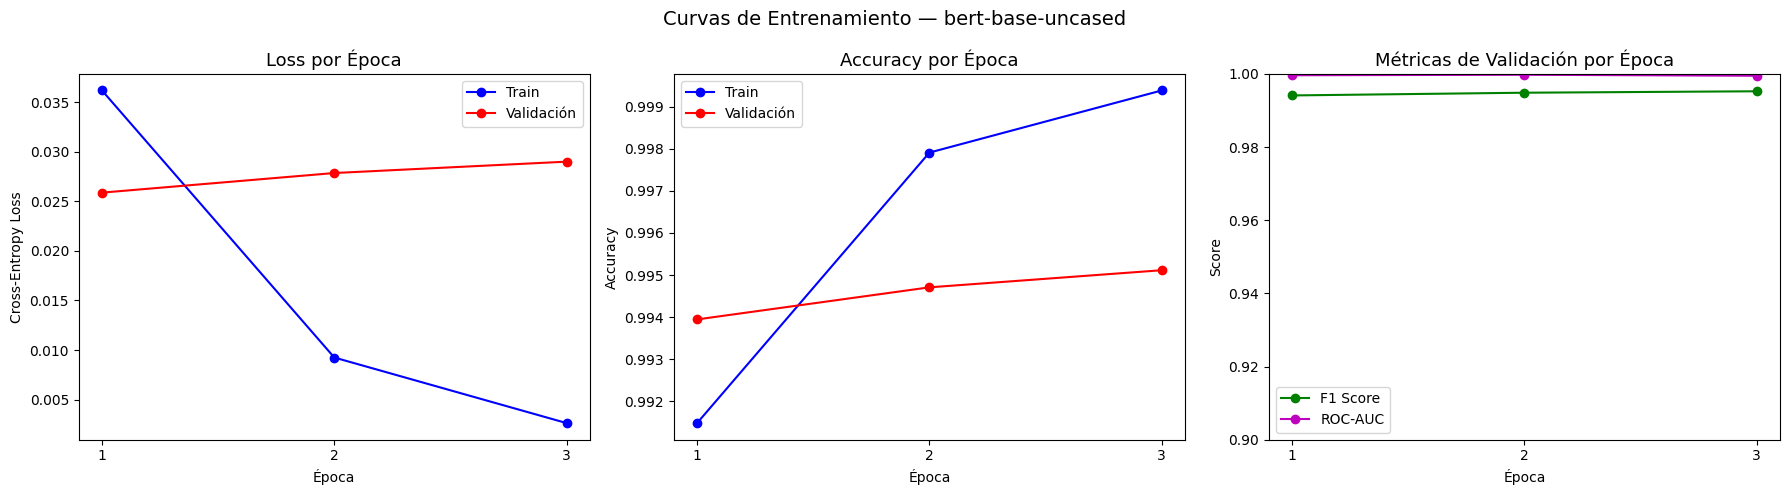

In [40]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Curva de Loss
axes[0].plot(epochs_range, history['train_loss'], 'b-o', label='Train')
axes[0].plot(epochs_range, history['val_loss'],   'r-o', label='Validación')
axes[0].set_title('Loss por Época', fontsize=13)
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()
axes[0].set_xticks(epochs_range)

# Curva de Accuracy
axes[1].plot(epochs_range, history['train_acc'], 'b-o', label='Train')
axes[1].plot(epochs_range, history['val_acc'],   'r-o', label='Validación')
axes[1].set_title('Accuracy por Época', fontsize=13)
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].set_xticks(epochs_range)

# F1 y AUC de validación
axes[2].plot(epochs_range, history['val_f1'],  'g-o', label='F1 Score')
axes[2].plot(epochs_range, history['val_auc'], 'm-o', label='ROC-AUC')
axes[2].set_title('Métricas de Validación por Época', fontsize=13)
axes[2].set_xlabel('Época')
axes[2].set_ylabel('Score')
axes[2].set_ylim([0.9, 1.0])  # zoom en la región alta
axes[2].legend()
axes[2].set_xticks(epochs_range)

plt.suptitle(f'Curvas de Entrenamiento — {MODEL_NAME}', fontsize=14)
plt.tight_layout()
plt.savefig('../reports/figures/bert_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Evaluación Final en Test

Cargamos el MEJOR modelo guardado (el de la época con mayor F1 en validación) y lo evaluamos en el conjunto de test — datos que el modelo **nunca vio** durante entrenamiento ni validación.

In [41]:
# Cargar el mejor modelo guardado
print(f'Cargando mejor modelo desde {MODEL_OUTPUT_DIR}...')
best_model = BertForSequenceClassification.from_pretrained(MODEL_OUTPUT_DIR)
best_model = best_model.to(DEVICE)

# Evaluación final en test
print('Evaluando en conjunto de TEST...')
_, test_acc, test_preds, test_labels, test_probs = evaluate(best_model, test_loader, DEVICE)

test_f1  = f1_score(test_labels, test_preds)
test_auc = roc_auc_score(test_labels, test_probs)

print(f'\n{"="*55}')
print(f'  RESULTADOS FINALES EN TEST — BERT')
print(f'{"="*55}')
print(classification_report(test_labels, test_preds, target_names=['HAM', 'PHISHING']))
print(f'  ROC-AUC : {test_auc:.4f}')
print(f'  F1 Score: {test_f1:.4f}')
print(f'  Accuracy: {test_acc:.4f}')

Cargando mejor modelo desde ../models/bert_phishing...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9263.02it/s]


Evaluando en conjunto de TEST...



  RESULTADOS FINALES EN TEST — BERT
              precision    recall  f1-score   support

         HAM       0.99      1.00      0.99      9592
    PHISHING       1.00      0.99      0.99     10109

    accuracy                           0.99     19701
   macro avg       0.99      0.99      0.99     19701
weighted avg       0.99      0.99      0.99     19701

  ROC-AUC : 0.9996
  F1 Score: 0.9945
  Accuracy: 0.9944


## 14. Inferencia — Clasificar Emails Nuevos

Demostración de cómo usar el modelo para clasificar emails que nunca vio.

In [44]:
def clasificar_email(texto: str, model, tokenizer, device, max_len=128) -> dict:
    """
    Clasifica un email como HAM (0) o PHISHING (1).
    
    Retorna diccionario con la clase predicha y la confianza.
    """
    model.eval()  # modo evaluación
    
    # Tokenizar el texto
    encoding = tokenizer(
        texto,
        max_length         = max_len,
        truncation         = True,
        padding            = 'max_length',
        return_attention_mask = True,
        return_tensors     = 'pt',
    )
    
    # Mover a GPU y hacer predicción
    with torch.no_grad():
        with autocast():
            output = model(
                input_ids      = encoding['input_ids'].to(device),
                attention_mask = encoding['attention_mask'].to(device),
            )
    
    # Convertir logits a probabilidades
    probs = torch.softmax(output.logits, dim=-1)[0].cpu().numpy()
    clase = int(probs.argmax())
    
    return {
        'clase'     : 'PHISHING' if clase == 1 else 'HAM',
        'confianza' : float(probs[clase]),
        'prob_ham'  : float(probs[0]),
        'prob_phish': float(probs[1]),
    }


# === PRUEBA CON EJEMPLOS ===
ejemplos_prueba = [
    "Click here to verify your PayPal account immediately or it will be suspended. Login: http://paypal-verify.suspicious.com",
    "Hi team, please review the Q3 budget report attached and let me know your thoughts before Friday's meeting.",
    "Congratulations! You have been selected to receive a $500 Amazon gift card. Claim now before it expires!",
    "Can we reschedule the 3pm call to 4pm? I have a conflict with the client meeting.",
]

print('=== CLASIFICACIÓN DE EMAILS DE PRUEBA ===\n')
for email in ejemplos_prueba:
    resultado = clasificar_email(email, best_model, tokenizer, DEVICE)
    emoji = '🔴' if resultado['clase'] == 'PHISHING' else '🟢'
    print(f'{emoji} {resultado["clase"]} (confianza: {resultado["confianza"]:.1%})')
    print(f'   Email  : {email[:100]}...' if len(email) > 100 else f'   Email  : {email}')
    print(f'   P(HAM) : {resultado["prob_ham"]:.4f} | P(PHISH): {resultado["prob_phish"]:.4f}\n')

=== CLASIFICACIÓN DE EMAILS DE PRUEBA ===

🔴 PHISHING (confianza: 100.0%)
   Email  : Click here to verify your PayPal account immediately or it will be suspended. Login: http://paypal-v...
   P(HAM) : 0.0000 | P(PHISH): 1.0000

🟢 HAM (confianza: 100.0%)
   Email  : Hi team, please review the Q3 budget report attached and let me know your thoughts before Friday's m...
   P(HAM) : 1.0000 | P(PHISH): 0.0000

🔴 PHISHING (confianza: 99.8%)
   Email  : Congratulations! You have been selected to receive a $500 Amazon gift card. Claim now before it expi...
   P(HAM) : 0.0019 | P(PHISH): 0.9980

🟢 HAM (confianza: 100.0%)
   Email  : Can we reschedule the 3pm call to 4pm? I have a conflict with the client meeting.
   P(HAM) : 1.0000 | P(PHISH): 0.0000



## 15. Conclusiones y Próximos Pasos

### Lo que logramos en este notebook:
- Fine-tuning de BERT-base para clasificación de phishing
- Entrenamiento con mixed precision (fp16) en RTX 5060
- Evaluación completa con classification report, ROC-AUC, F1
- Modelo guardado en formato Hugging Face (reutilizable)

### Comparativa esperada de resultados:
| Modelo | F1 esperado | ROC-AUC esperado |
|---|---|---|
| Logistic Regression | 0.97-0.98 | 0.98-0.99 |
| Random Forest | 0.97-0.98 | 0.98-0.99 |
| XGBoost/LightGBM | 0.98-0.99 | 0.99 |
| BERT-base | **0.99+** | **0.999+** |

### Posibles mejoras:
1. **DistilBERT**: 60% más rápido, 97% del rendimiento de BERT — ideal para producción
2. **RoBERTa**: Versión mejorada de BERT, generalmente superior en clasificación
3. **Aumentar MAX_LEN a 256** si hay emails importantes que se truncan
4. **Early stopping** automático para detener si val_loss no mejora después de N épocas
5. **Hyperparameter search** con Optuna para encontrar el LR y batch size óptimos

---
**¡El modelo está listo!** Puedes usarlo con `clasificar_email()` para clasificar cualquier email nuevo.